In [1]:
import pandas as pd

df = pd.read_csv("data/Sample - Superstore.csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
df.to_csv("outputs/dataset_copy.csv", index=False)

In [3]:

# STEP 1: Key Business Metrics

total_revenue = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_units = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()

profit_margin = (
    total_profit / total_revenue * 100
    if total_revenue != 0 else 0
)

average_order_value = (
    total_revenue / total_orders
    if total_orders != 0 else 0
)

print("========== SALES ANALYSIS ==========")
print(f"Total Revenue:      {total_revenue:,.2f}")
print(f"Total Profit:       {total_profit:,.2f}")
print(f"Profit Margin:      {profit_margin:.2f}%")
print(f"Average Order Value:{average_order_value:,.2f}")
print(f"Total Units Sold:   {total_units:,}")
print(f"Total Orders:       {total_orders:,}")

========== SALES ANALYSIS ==========
Total Revenue:      2,297,200.86
Total Profit:       286,397.02
Profit Margin:      12.47%
Average Order Value:458.61
Total Units Sold:   37,873
Total Orders:       5,009


In [4]:

# STEP 2: Data Quality Check

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing values in each column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate rows: 0

Data types:
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              st

In [5]:

# STEP 3: Check Date Columns

print("All columns:")
print(df.columns.tolist())

print("\nFirst 5 order dates:")
print(df["Order Date"].head())

print("\nFirst 5 ship dates:")
print(df["Ship Date"].head())

All columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

First 5 order dates:
0     11/8/2016
1     11/8/2016
2     6/12/2016
3    10/11/2015
4    10/11/2015
Name: Order Date, dtype: str

First 5 ship dates:
0    11/11/2016
1    11/11/2016
2     6/16/2016
3    10/18/2015
4    10/18/2015
Name: Ship Date, dtype: str


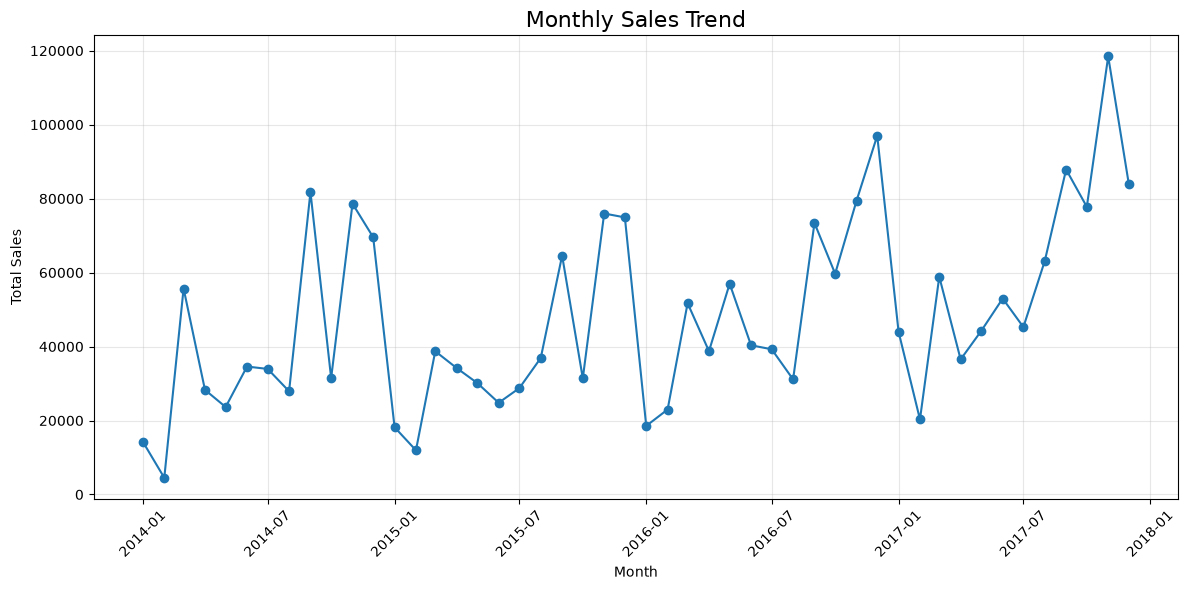

Monthly sales chart saved in outputs/monthly_sales_trend.png


,Total Sales
Order Date,
2014-01-01,14236.8950
2014-02-01,4519.8920
2014-03-01,55691.0090
2014-04-01,28295.3450
2014-05-01,23648.2870
2014-06-01,34595.1276
2014-07-01,33946.3930
2014-08-01,27909.4685
2014-09-01,81777.3508


In [6]:

# STEP 4: Monthly Sales Trend

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Create outputs folder if it does not exist
Path("outputs").mkdir(parents=True, exist_ok=True)

# Convert Order Date to datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

# Remove rows where order date or sales is missing
monthly_df = df.dropna(subset=["Order Date", "Sales"]).copy()

# Group sales by month
monthly_sales = (
    monthly_df
    .set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
)

# Plot monthly sales
plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save high-resolution chart
plt.savefig(
    "outputs/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Monthly sales chart saved in outputs/monthly_sales_trend.png")
display(monthly_sales.to_frame(name="Total Sales"))

Quarterly Sales Summary:


,Total Sales
Order Date,
2014Q1,74447.7960
2014Q2,86538.7596
2014Q3,143633.2123
2014Q4,179627.7302
2015Q1,68851.7386
2015Q2,89124.1870
2015Q3,130259.5752
2015Q4,182297.0082
2016Q1,93237.1810


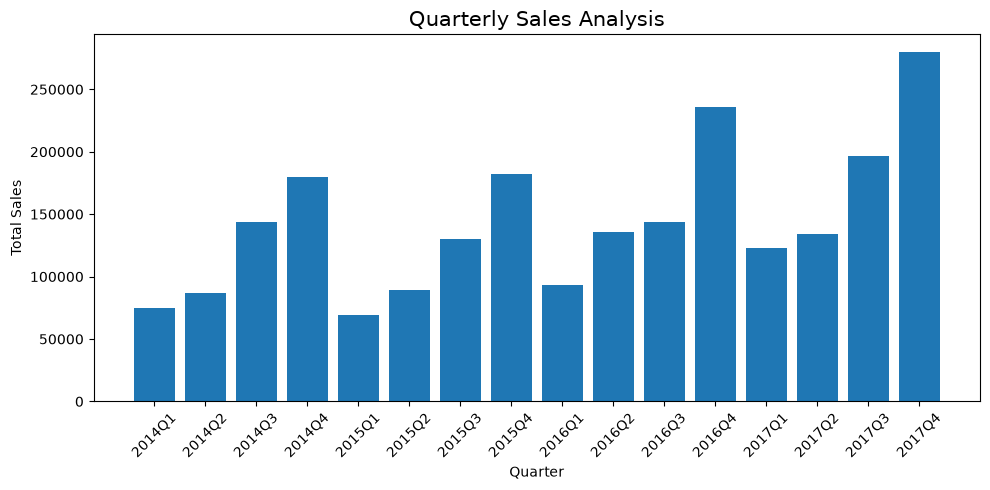

Chart saved: outputs/quarterly_sales_analysis.png


In [7]:

# STEP 5: Quarterly Sales Analysis

quarterly_sales = (
    df.dropna(subset=["Order Date", "Sales"])
      .set_index("Order Date")["Sales"]
      .resample("QS")
      .sum()
)

# Make quarter labels
quarterly_sales.index = quarterly_sales.index.to_period("Q").astype(str)

print("Quarterly Sales Summary:")
display(quarterly_sales.to_frame(name="Total Sales"))

# Plot
plt.figure(figsize=(10, 5))
plt.bar(quarterly_sales.index, quarterly_sales.values)
plt.title("Quarterly Sales Analysis", fontsize=15)
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "outputs/quarterly_sales_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Chart saved: outputs/quarterly_sales_analysis.png")

Seasonal Sales Summary:


,Total Sales
Season,
Winter,479969.5905
Spring,497796.4291
Summer,459000.8393
Fall,860434.0014


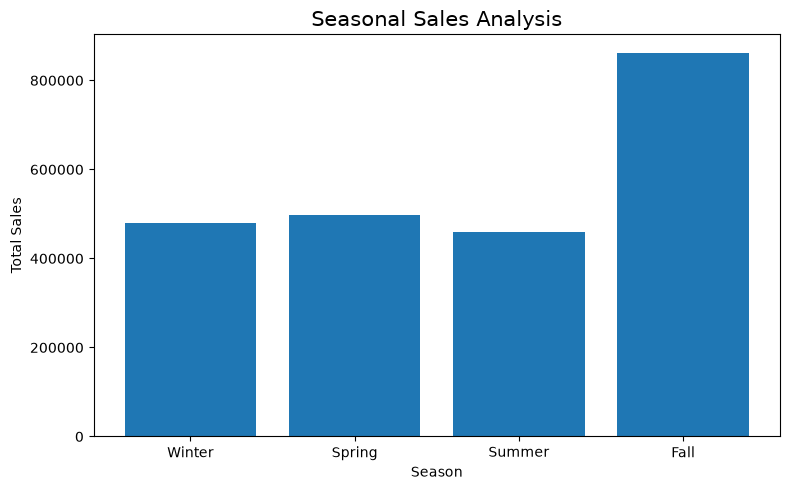

Chart saved: outputs/seasonal_sales_analysis.png


In [8]:

# STEP 6: Seasonal Sales Analysis

season_map = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Fall",
    10: "Fall",
    11: "Fall"
}

season_df = df.dropna(subset=["Order Date", "Sales"]).copy()
season_df["Season"] = season_df["Order Date"].dt.month.map(season_map)

season_order = ["Winter", "Spring", "Summer", "Fall"]

seasonal_sales = (
    season_df.groupby("Season")["Sales"]
    .sum()
    .reindex(season_order)
)

print("Seasonal Sales Summary:")
display(seasonal_sales.to_frame(name="Total Sales"))

plt.figure(figsize=(8, 5))
plt.bar(seasonal_sales.index, seasonal_sales.values)
plt.title("Seasonal Sales Analysis", fontsize=15)
plt.xlabel("Season")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig(
    "outputs/seasonal_sales_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Chart saved: outputs/seasonal_sales_analysis.png")

Category Performance Summary:


,Total_Sales,Total_Profit,Units_Sold,Unique_Products,Profit_Margin_%
Category,,,,,
Technology,836154.03,145454.95,6939,412,17.40
Furniture,741999.80,18451.27,8028,380,2.49
Office Supplies,719047.03,122490.80,22906,1058,17.04


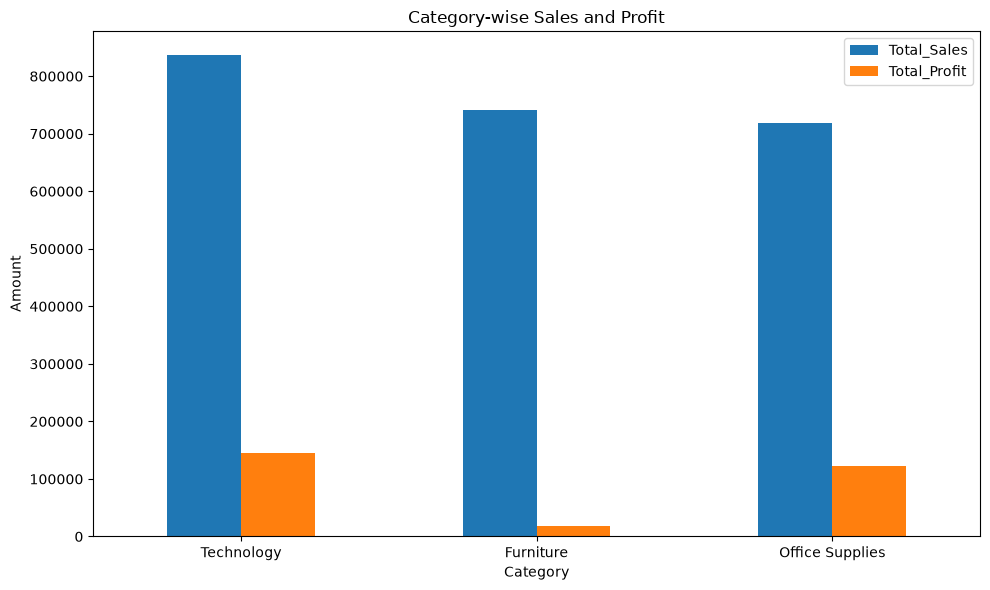

Category summary and chart saved in outputs/


In [9]:

# STEP 7: Category-wise Sales and Profit

category_summary = (
    df.groupby("Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Units_Sold=("Quantity", "sum"),
          Unique_Products=("Product Name", "nunique")
      )
      .sort_values("Total_Sales", ascending=False)
)

category_summary["Profit_Margin_%"] = (
    category_summary["Total_Profit"]
    / category_summary["Total_Sales"].replace(0, float("nan"))
    * 100
)

print("Category Performance Summary:")
display(category_summary.round(2))

# Save summary as CSV
category_summary.to_csv("outputs/category_performance.csv")

# Plot category sales and profit
category_summary[["Total_Sales", "Total_Profit"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Category-wise Sales and Profit")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/category_sales_profit.png", dpi=300, bbox_inches="tight")
plt.show()

print("Category summary and chart saved in outputs/")

Top 10 Products by Total Sales:


,Total_Sales,Total_Profit,Units_Sold
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08,6
HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00,39
GBC DocuBind TL300 Electric Binding System,19823.48,2233.51,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98,48
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98,12
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27


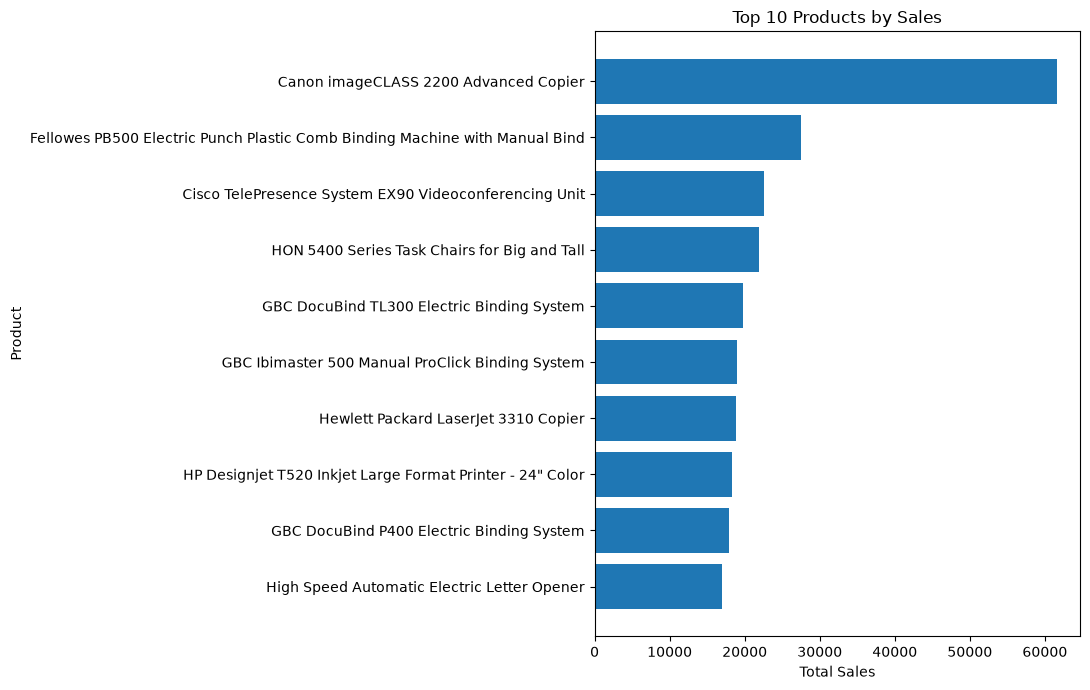

Product summary and chart saved in outputs/


In [10]:

# STEP 8: Top 10 Products by Sales

product_summary = (
    df.groupby("Product Name")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Units_Sold=("Quantity", "sum")
      )
      .sort_values("Total_Sales", ascending=False)
)

print("Top 10 Products by Total Sales:")
display(product_summary.head(10).round(2))

# Save complete product summary
product_summary.to_csv("outputs/product_performance.csv")

top10 = product_summary.head(10).sort_values("Total_Sales")

plt.figure(figsize=(11, 7))
plt.barh(top10.index, top10["Total_Sales"])
plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig("outputs/top_10_products.png", dpi=300, bbox_inches="tight")
plt.show()

print("Product summary and chart saved in outputs/")

In [11]:

# STEP 9: High-Margin Products

product_margin = product_summary.copy()

product_margin["Profit_Margin_%"] = (
    product_margin["Total_Profit"]
    / product_margin["Total_Sales"].replace(0, float("nan"))
    * 100
)

minimum_sales = df["Sales"].sum() * 0.01

high_margin_products = (
    product_margin[
        (product_margin["Total_Sales"] >= minimum_sales)
        & (product_margin["Profit_Margin_%"].notna())
    ]
    .sort_values("Profit_Margin_%", ascending=False)
    .head(10)
)

print("Top 10 High-Margin Products (minimum 1% of total dataset sales):")
display(high_margin_products.round(2))

high_margin_products.to_csv("outputs/high_margin_products.csv")

print("High-margin product table saved in outputs/")

Top 10 High-Margin Products (minimum 1% of total dataset sales):


,Total_Sales,Total_Profit,Units_Sold,Profit_Margin_%
Product Name,,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20,40.91
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31,28.24


High-margin product table saved in outputs/


In [12]:

# STEP 9: High-Margin Products

product_margin = product_summary.copy()

product_margin["Profit_Margin_%"] = (
    product_margin["Total_Profit"]
    / product_margin["Total_Sales"].replace(0, float("nan"))
    * 100
)

minimum_sales = df["Sales"].sum() * 0.01

high_margin_products = (
    product_margin[
        (product_margin["Total_Sales"] >= minimum_sales)
        & (product_margin["Profit_Margin_%"].notna())
    ]
    .sort_values("Profit_Margin_%", ascending=False)
    .head(10)
)

print("Top 10 High-Margin Products (minimum 1% of total dataset sales):")
display(high_margin_products.round(2))

high_margin_products.to_csv("outputs/high_margin_products.csv")

print("High-margin product table saved in outputs/")

Top 10 High-Margin Products (minimum 1% of total dataset sales):


,Total_Sales,Total_Profit,Units_Sold,Profit_Margin_%
Product Name,,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20,40.91
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31,28.24


High-margin product table saved in outputs/


,Total_Sales,Total_Profit,Total_Orders
Region,,,
West,725457.82,108418.45,1611
East,678781.24,91522.78,1401
Central,501239.89,39706.36,1175
South,391721.90,46749.43,822


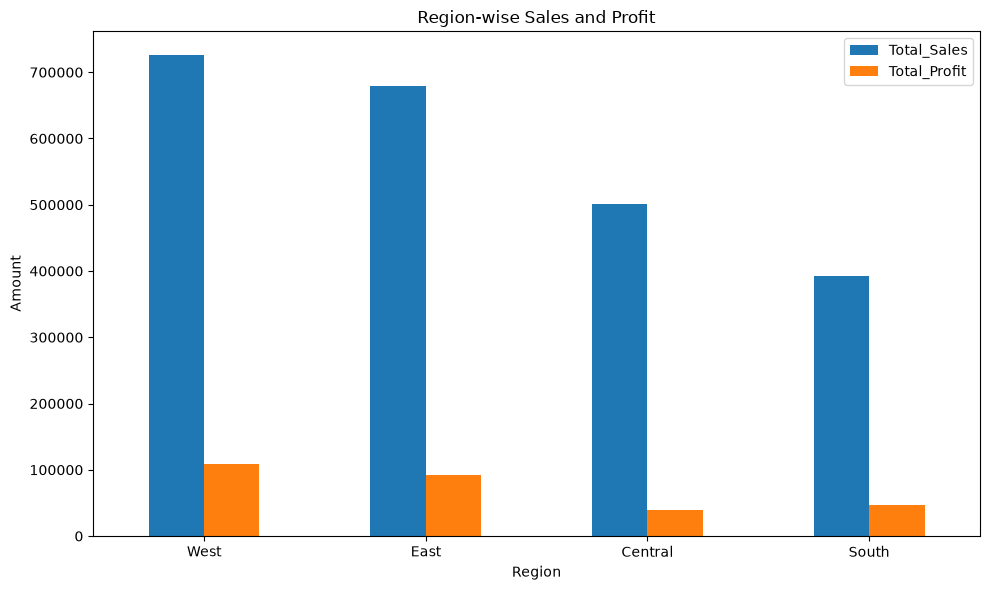

In [13]:

# Region-wise sales and profit analysis
region_summary = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(region_summary.round(2))
region_summary.to_csv("outputs/region_performance.csv")

region_summary[["Total_Sales", "Total_Profit"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Region-wise Sales and Profit")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/region_sales_profit.png", dpi=300, bbox_inches="tight")
plt.show()

,Total_Sales
State,
New Jersey,35764.31
Kentucky,36591.75
Georgia,49095.84
Indiana,53555.36
North Carolina,55603.16
Virginia,70636.72
Michigan,76269.61
Ohio,78258.14
Illinois,80166.10


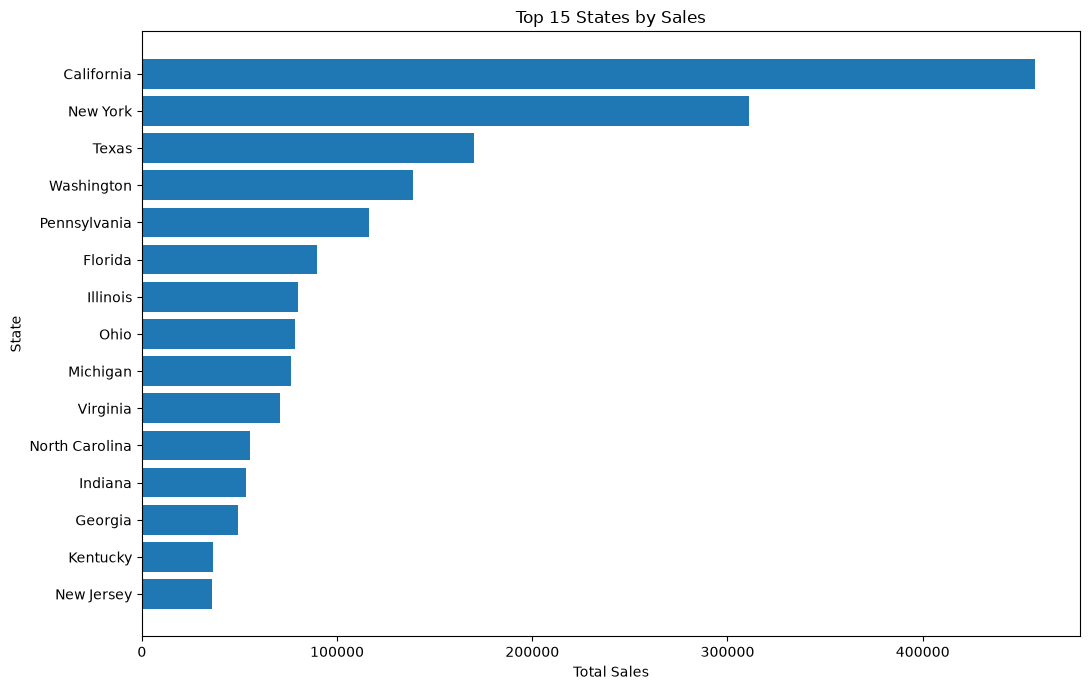

In [14]:

# Top 15 states by total sales
state_sales = df.groupby("State")["Sales"].sum().sort_values(ascending=False)
top_states = state_sales.head(15).sort_values()

display(top_states.to_frame(name="Total_Sales").round(2))
top_states.to_csv("outputs/top_15_states.csv")

plt.figure(figsize=(11, 7))
plt.barh(top_states.index, top_states.values)
plt.title("Top 15 States by Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.savefig("outputs/top_15_states_sales.png", dpi=300, bbox_inches="tight")
plt.show()

,Total_Sales,Total_Profit,Units_Sold,Total_Orders
Segment,,,,
Consumer,1161401.34,134119.21,19521,2586
Corporate,706146.37,91979.13,11608,1514
Home Office,429653.15,60298.68,6744,909


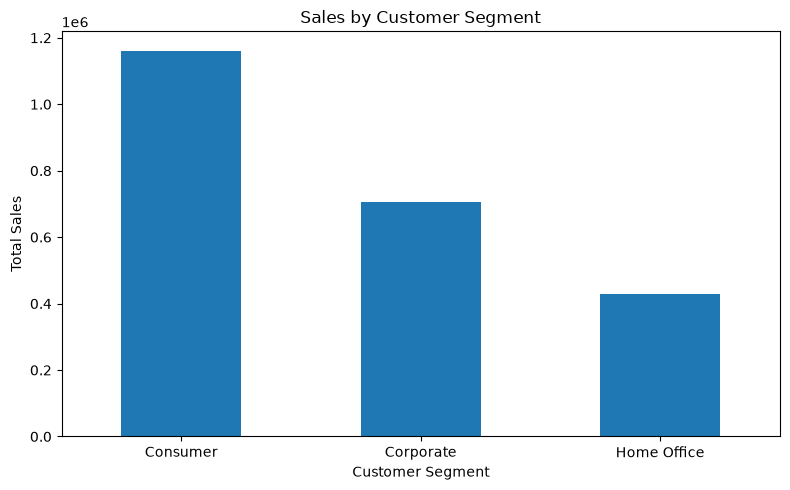

In [15]:

# Customer segment analysis
segment_summary = (
    df.groupby("Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(segment_summary.round(2))
segment_summary.to_csv("outputs/customer_segment_analysis.csv")

segment_summary["Total_Sales"].plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/customer_segment_sales.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:

from pathlib import Path

# Prepare findings from the analysis already completed
best_category = category_summary["Total_Sales"].idxmax()
best_profit_category = category_summary["Total_Profit"].idxmax()
best_region = region_summary["Total_Sales"].idxmax()
best_state = state_sales.idxmax()
best_segment = segment_summary["Total_Sales"].idxmax()
best_season = seasonal_sales.idxmax()
best_quarter = quarterly_sales.idxmax()
best_month = monthly_sales.idxmax()

top_product = product_summary["Total_Sales"].idxmax()
top_profit_product = product_summary["Total_Profit"].idxmax()

# Build a professional README
readme = f"""# Sales Data Analysis
### CodeNova Data Science Internship — Task 1

## 1. Project Overview

This project presents an exploratory sales data analysis of the Sample Superstore dataset using Python. The objective is to evaluate sales performance, profitability, product performance, and time-based and geographic sales patterns.

The analysis transforms raw sales records into summary metrics, visualizations, and business-oriented observations that can support data-informed decision-making.

## 2. Business Objectives

- Calculate key performance indicators (KPIs), including total sales revenue, total profit, profit margin, average order value, and units sold.
- Identify monthly, quarterly, and seasonal sales patterns.
- Compare sales and profitability across product categories and individual products.
- Examine sales performance across regions and states.
- Analyze customer-segment performance.
- Present findings through clear visualizations and exported summary tables.

## 3. Dataset Description

**Dataset:** Sample - Superstore.csv

The dataset contains transaction-level information used to analyze orders, products, sales, profits, dates, locations, and customer segments.

Key fields used in this project include:

| Field | Purpose |
|---|---|
| Order ID | Count unique orders |
| Order Date | Analyze sales over time |
| Sales | Measure sales revenue |
| Profit | Evaluate profitability |
| Quantity | Measure units sold |
| Category | Compare product categories |
| Product Name | Analyze individual products |
| Region and State | Analyze geographic performance |
| Segment | Compare customer groups |

The dataset is loaded using Pandas. Date fields are converted to datetime format where required, and data quality checks are performed before analysis.

## 4. Tools and Technologies

- **Python** — analysis and calculations
- **Pandas** — data cleaning, grouping, aggregation, and analysis
- **Matplotlib** — data visualization
- **Jupyter Notebook** — interactive analysis and documentation

## 5. Key Performance Indicators

| Metric | Result |
|---|---:|
| Total Sales Revenue | {total_revenue:,.2f} |
| Total Profit | {total_profit:,.2f} |
| Profit Margin | {profit_margin:.2f}% |
| Average Order Value (AOV) | {average_order_value:,.2f} |
| Total Units Sold | {total_units:,} |
| Unique Orders | {total_orders:,} |

**Metric definitions**

- **Total Sales Revenue:** Sum of the Sales column.
- **Total Profit:** Sum of the Profit column.
- **Profit Margin:** Total Profit divided by Total Sales Revenue, multiplied by 100.
- **Average Order Value (AOV):** Total Sales Revenue divided by the number of unique Order IDs.
- **Total Units Sold:** Sum of the Quantity column.
- **Unique Orders:** Number of distinct Order IDs.

*Note: Currency formatting follows the source values; a currency symbol is not specified because the dataset's currency has not been independently verified.*

## 6. Analysis Performed

### 6.1 Time-Based Sales Analysis

Sales were aggregated by month, quarter, and season to examine changes in sales performance over time.

- Monthly sales trend analysis
- Quarterly sales comparison
- Seasonal sales comparison

### 6.2 Category and Product Analysis

Product performance was evaluated using sales, profit, quantity sold, and profit margin.

- Category-level sales and profit comparison
- Top 10 products by total sales
- Product-level profitability analysis

### 6.3 Geographic Analysis

Sales performance was compared across regions and states to identify locations with relatively high sales.

- Region-level sales and profit
- Top 15 states by sales

### 6.4 Customer Segment Analysis

Sales, profit, units sold, and unique orders were compared across the available customer segments.

*The Segment field represents customer groups in the dataset; it is not age- or gender-based demographic data.*

## 7. Key Findings

The following findings are calculated from the dataset analyzed in this project:

- **Leading sales category:** {best_category}
- **Leading profit category:** {best_profit_category}
- **Leading sales region:** {best_region}
- **Leading state by sales:** {best_state}
- **Leading customer segment by sales:** {best_segment}
- **Highest-sales season:** {best_season}
- **Highest-sales quarter:** {best_quarter}
- **Highest-sales month:** {best_month:%B %Y}
- **Highest-sales product:** {top_product}
- **Highest-total-profit product:** {top_profit_product}

These findings identify the top-performing groups by the stated measures. High sales do not necessarily imply high profitability; sales and profit should be assessed together.

## 8. Business Recommendations

Based on the analysis framework and observed performance, the following actions are worth considering:

1. **Improve category-level decisions:** Review both sales and profit by category before allocating promotional budgets.
2. **Investigate product profitability:** Compare high-sales products with their profit margins to avoid prioritizing revenue alone.
3. **Plan around sales patterns:** Use monthly and quarterly trends to inform inventory, staffing, and promotional planning.
4. **Review geographic performance:** Investigate differences in regional and state sales to identify opportunities for further analysis.
5. **Understand customer segments:** Compare sales and order patterns across segments when planning customer-focused campaigns.
6. **Validate before acting:** Confirm that observed patterns persist over time before making major operational or financial decisions.

These recommendations are starting points for further investigation, not proof of causation.

## 9. Visualizations and Output Files

Charts are exported as high-resolution PNG images, and summary tables are saved as CSV files in the `outputs/` directory.

| File | Description |
|---|---|
| `monthly_sales_trend.png` | Monthly sales trend |
| `quarterly_sales_analysis.png` | Quarterly sales comparison |
| `seasonal_sales_analysis.png` | Seasonal sales comparison |
| `category_sales_profit.png` | Category-level sales and profit |
| `top_10_products.png` | Top 10 products by sales |
| `region_sales_profit.png` | Regional sales and profit |
| `top_15_states_sales.png` | Top 15 states by sales |
| `customer_segment_sales.png` | Sales by customer segment |
| `category_performance.csv` | Category performance metrics |
| `product_performance.csv` | Product performance metrics |
| `high_margin_products.csv` | Selected higher-margin products |
| `region_performance.csv` | Regional performance metrics |
| `top_15_states.csv` | State-level sales summary |
| `customer_segment_analysis.csv` | Customer-segment summary |

## 10. Project Structure

```text
CodeNova-Sales-Analysis/
├── data/
│   └── Sample - Superstore.csv
├── outputs/
│   ├── monthly_sales_trend.png
│   ├── quarterly_sales_analysis.png
│   ├── seasonal_sales_analysis.png
│   ├── category_sales_profit.png
│   ├── top_10_products.png
│   ├── region_sales_profit.png
│   ├── top_15_states_sales.png
│   └── customer_segment_sales.png
├── Sales_Data_Analysis.ipynb
├── sales_analysis.py
└── README.md
```

The `outputs/` directory also contains the CSV summary tables generated during the analysis.

## 11. How to Run the Project

1. Install Python and Jupyter Notebook, or use Visual Studio Code with the Python and Jupyter extensions.
2. Install the required libraries:

   ```bash
   python -m pip install pandas matplotlib jupyter
   ```

3. Open the project folder in Visual Studio Code.
4. Select a Python environment in which the required libraries are installed.
5. Open `Sales_Data_Analysis.ipynb`.
6. Run the notebook cells in order from top to bottom.

Ensure that `data/Sample - Superstore.csv` exists at the expected relative path and that the `outputs/` directory is writable.

## 12. Limitations

- Findings describe the provided dataset and may not generalize to other businesses or periods.
- Profit margin is calculated from the aggregate profit and sales values; individual product margins can differ.
- Seasonal labels use a calendar-based Northern Hemisphere season mapping.
- Customer-segment analysis is limited to the groups available in the dataset.
- The analysis identifies patterns and associations; it does not establish the causes of sales or profit changes.
- Recommendations should be validated against business context and additional evidence before implementation.

## 13. Conclusion

This project demonstrates an end-to-end exploratory sales analysis workflow using Python, Pandas, and Matplotlib. It combines KPI calculation, time-based analysis, product and category comparisons, geographic analysis, customer-segment analysis, and visual reporting.

The resulting notebook, charts, and summary tables provide a foundation for understanding sales performance and identifying areas for further business investigation.

---

**Project:** Sales Data Analysis  
**Program:** CodeNova Data Science Internship  
**Task:** Task 1
"""

Path("README.md").write_text(readme, encoding="utf-8")

print("Professional README.md created successfully!")
print("File location:", Path("README.md").resolve())

Professional README.md created successfully!
File location: C:\Users\admin\Desktop\CodeNova-Sales-Analysis\README.md
